# Training the snake identifier

This notebook trains our species model and collects every training run behind it. We first describe the model in plain words, then train the final configuration once, end to end, so you can watch it learn. After that we gather all 30 training runs we made for this milestone from the saved results tables: the encoder comparison, the species head and losses, the noise floor, two loss settings, cropping the snake first, and the retrains of the tuning search's winners. We end with our final model against the published SnakeCLEF 2021 model.

It runs on Kaggle with a T4 GPU. The training run takes about an hour and a half; everything else takes seconds. It reads the cleaned dataset, the snake masks, the experiment subset and the detector's boxes from the cropping notebook, plus the committed tables in `results/m3/summary/`.

## Setup

We pin the three libraries whose versions the recorded runs used, and silence download bars and warnings.

In [1]:
%pip install -q timm==1.0.31 albumentations==2.0.8 scikit-learn==1.9.1
import json, logging, os, sys, warnings
from pathlib import Path

os.environ["NO_ALBUMENTATIONS_UPDATE"] = "1"      # no "new version available" check
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"  # no download bar for the ImageNet weights
warnings.filterwarnings("ignore")

import albumentations, kagglehub, sklearn, timm, torch
import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path("../src").resolve()))  # the project's code
from serpentguard.models import build_model
from serpentguard.train import train

logging.basicConfig(format="%(message)s", stream=sys.stdout, force=True)
logging.getLogger("serpentguard").setLevel(logging.INFO)  # train() reports each evaluation
pd.set_option("display.precision", 3)
print(f"timm {timm.__version__}, albumentations {albumentations.__version__}, "
      f"scikit-learn {sklearn.__version__}, {torch.cuda.device_count()} GPU(s)")

Note: you may need to restart the kernel to use updated packages.
timm 1.0.31, albumentations 2.0.8, scikit-learn 1.9.1, 2 GPU(s)


## 1. The model

Our model, SnakeID, is small enough for a phone. It takes a 320 × 320 photo cropped around the snake by the detector (the cropping notebook trains that detector). A MobileViT-S encoder, pretrained on ImageNet and loaded with the timm library, turns the crop into a 10 × 10 grid of 640 features, which we average into 640 numbers. A linear layer squeezes these to 256 numbers. Scaled to length 1, those 256 numbers are the photo's **embedding**: photos of the same species should get embeddings that point the same way.

Four heads read the 256 numbers. The **species head** scores all 184 species by the cosine between the embedding and one learned direction per species. It is trained with the **ArcFace** loss, which adds a margin to the right species' angle, so photos of one species have to bunch tightly. Three small linear heads guess the **genus** (69), the **family** (13) and the **WHO category** (not listed, Category 2, Category 1); the safety layer uses them as extra danger signals and as a fallback when the species is unclear. The average embedding of each species is its **prototype**: a second way to rank species, and the way to add a new species from a few photos without retraining.

![The SnakeID model, from the detector's crop to the decision layer](../documentation/milestone%203/assets/m3_snakeid.png)

## 2. One training run of the final model

These are the settings of the final model, the recorded run saved as `H1_top1_s1` (H1 is the tuning search, top 1 its best setting, s1 the seed). The learning rate, weight decay, ArcFace margin and augmentation strength come from the tuning search; the other choices are the winners of the comparisons in section 3. Training uses AdamW, with the pretrained encoder learning ten times slower than the new layers, a one-epoch warm-up and then a cosine decay. Batches are drawn with rare species and WHO-listed species weighted up. Every second epoch we score the 17,151 validation photos, and we keep the best epoch.

In [2]:
cfg = dict(
    run_id="H1_top1_s1", seed=1,
    # the model
    encoder="mobilevit_s", input_size=320, pooling="gap", embedding_dim=256,
    head="arcface", losses=["arcface"], arcface_s=30.0, arcface_m=0.35616842912779545,
    hierarchy=True,     # genus and family heads on
    danger_weight=1.0,  # no extra penalty for calling a WHO-listed snake "not listed"
    mask_head=False,    # no snake-mask head
    # the photo: crop to the detector's box (front end "F1")
    front_end="F1", box_source="predicted", mask_source="predicted",
    aug_strength=0.7454942047909925,  # 0.75 of the default augmentation
    # training
    epochs=20, batch_size=64, sampler="weighted", lr=0.0009530320008110496,
    weight_decay=0.0015566936015792908, warmup_epochs=1, eval_every=2,
    # not used by this run; kept so the saved config.yaml lists every setting
    mask_keep=0.2, mask_weight=1.0, triplet_margin=0.2, triplet_weight=1.0, exclude_species=[],
)

Built from these settings, the model gives one output per head for each photo. A quick check on two random images:

In [3]:
model = build_model(cfg).eval()
with torch.no_grad():
    outputs = model(torch.rand(2, 3, 320, 320))
for name, value in outputs.items():
    if value is not None:
        print(f"{name:16} {tuple(value.shape)}")
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f} million parameters")

embedding        (2, 256)
features         (2, 256)
species_logits   (2, 184)
genus_logits     (2, 69)
family_logits    (2, 13)
who_logits       (2, 3)
5.2 million parameters


The photos come from three Kaggle datasets, downloaded by handle: the cleaned dataset, the snake masks and the experiment subset (16% of the training photos, built in the subset notebook). The detector's boxes come from the cropping notebook's Kaggle run, which this notebook declares as an input. On Kaggle the new run is saved under `/kaggle/working`, elsewhere under `runs/` in the repo.

In [4]:
ON_KAGGLE = Path("/kaggle/working").exists()
OWNER = "puneetbajajiitm"


def dataset(slug):
    return Path(kagglehub.dataset_download(f"{OWNER}/{slug}"))


data_root = dataset("serpentguard-indian-snakes-clean")
masks_root = dataset("serpentguard-sam-masks")
subset_csv = dataset("serpentguard-m3-subset") / "subset.csv"
boxes = Path(kagglehub.notebook_output_download(f"{OWNER}/sg-m3-frontends"))
preds_root = next(boxes.rglob("frontend_preds.csv")).parent

out_dir = (Path("/kaggle/working") if ON_KAGGLE else Path("../runs")) / cfg["run_id"]
results = Path("../results/m3")  # the recorded runs, committed with the repo
print(f"{len(pd.read_csv(subset_csv)):,} training photos in the subset; detector boxes for "
      f"{len(pd.read_csv(preds_root / 'frontend_preds.csv')):,} photos")

13,925 training photos in the subset; detector boxes for 39,526 photos


Now the training itself. `train()` builds the model from `cfg`, trains it for 20 epochs on the subset's photos cropped to the detector's boxes, and scores the validation photos every second epoch, printing one line each time. It keeps the best epoch and saves everything the later notebooks read into the run folder: the weights (`best.pt`), the scores at each evaluation (`metrics.jsonl`), the final scores (`final_metrics.json`) and the model's outputs on the validation, calibration and unknown-species photos. On one T4 this takes about an hour and a half; the recorded run took 87 minutes.

In [5]:
train(cfg, out_dir, data_root, masks_root, subset_csv, preds_root=preds_root)
print("saved:", ", ".join(sorted(path.name for path in out_dir.iterdir())))

H1_top1_s1: read 39212 files (5386 MB, 0 missing) into the page cache in 56 s
H1_top1_s1 on Tesla T4: 13611 training photos after caps, 17151 val, 7999 calibration, 451 unknown; subset 40196d19a68e; front-end predictions cover {'train': 0.9997795900374697, 'val': 0.9995335548947584, 'calibration': 0.9998749843730467, 'unknown': 1.0}
H1_top1_s1 epoch 2/20: macro-F1 0.196, top-1 0.469, top-3 0.646, loss 13.649, lr 9.47e-04, 97 photos/s, data wait 1%, epoch 140 s + eval 75 s
H1_top1_s1 epoch 4/20: macro-F1 0.281, top-1 0.544, top-3 0.707, loss 10.668, lr 8.96e-04, 96 photos/s, data wait 1%, epoch 141 s + eval 76 s
H1_top1_s1 epoch 6/20: macro-F1 0.309, top-1 0.575, top-3 0.734, loss 8.951, lr 7.99e-04, 96 photos/s, data wait 1%, epoch 142 s + eval 76 s
H1_top1_s1 epoch 8/20: macro-F1 0.324, top-1 0.590, top-3 0.740, loss 7.804, lr 6.68e-04, 96 photos/s, data wait 1%, epoch 142 s + eval 70 s
H1_top1_s1 epoch 10/20: macro-F1 0.345, top-1 0.605, top-3 0.751, loss 7.145, lr 5.16e-04, 96 photo

How does this run compare with the recorded one? A fresh run is not bit-identical, because GPU kernels and the order in which the loader's workers deliver photos differ between sessions. Expect a fresh run to land within the ±0.005 noise floor of the recorded runs (section 3); the recorded runs are what the report quotes. *WHO-listed kept listed* is the share of photos of WHO-listed snakes whose first guess is also a WHO-listed species.

In [6]:
final = json.loads((out_dir / "final_metrics.json").read_text())
# the committed subset's SHA-256 starts with these 12 digits
assert final["run"]["subset_hash"].startswith("40196d19a68e"), "the run read a different subset"
runs = pd.read_csv(results / "summary" / "model_runs.csv").set_index("run")
this_run = {"macro-F1": final["head"]["macro_f1"], "top-1": final["head"]["top1"],
            "top-3": final["head"]["top3"], "WHO-listed kept listed": final["safety"]["who_recall_raw"],
            "best epoch": final["run"]["best_epoch"], "minutes": final["timing"]["total_seconds"] / 60}
recorded = runs.loc["H1_top1_s1", ["macro-F1 head", "top-1", "top-3", "WHO recall (O2 raw)",
                                   "best epoch", "minutes"]].set_axis(list(this_run))
table = pd.DataFrame([this_run, recorded], index=["this run", "recorded run"])
table.loc["difference"] = table.loc["this run"] - table.loc["recorded run"]
table

,macro-F1,top-1,top-3,WHO-listed kept listed,best epoch,minutes
this run,3.672e-01,0.619,0.763,0.764,18.0,62.726
recorded run,3.669e-01,0.622,0.762,0.768,18.0,86.528
difference,3.665e-04,-0.003,0.001,-0.004,0.0,-23.801


The validation curve: macro-F1 at each evaluation, this run against the recorded one (whose `metrics.jsonl` is committed with the repo).

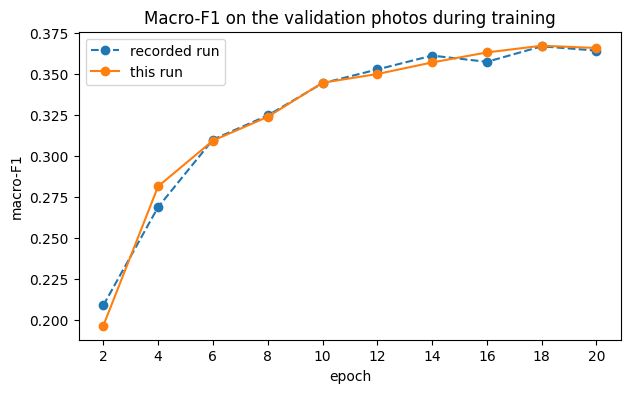

In [7]:
fresh = pd.read_json(out_dir / "metrics.jsonl", lines=True)
before = pd.read_json(results / "retrain" / "H1_top1_s1" / "metrics.jsonl", lines=True)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(before["epoch"], before["macro_f1"], "o--", label="recorded run")
ax.plot(fresh["epoch"], fresh["macro_f1"], "o-", label="this run")
ax.set(title="Macro-F1 on the validation photos during training", xlabel="epoch",
       ylabel="macro-F1", xticks=before["epoch"])
ax.legend()
plt.show()

## 3. Every training run we made

We ran this notebook once per configuration: 30 runs in all, each on a Kaggle T4 for 60 to 154 minutes. Every run saved the same files as the run above, and `results/m3/summary/model_runs.csv` collects their headline numbers; the tables below read it. Each stage started from the previous stage's winner. In every table the first column is the run's saved folder name, and **setting** says in plain words what that run changed. All scores are on the 17,151 validation photos:

- **macro-F1**: the F1 score of each species, averaged so that every species counts the same. This is our main score.
- **prototypes** and **balanced prototypes**: the same score when species are ranked by the nearest prototype instead of the species head. "Balanced" averages each photographer's photos first, so one prolific photographer can't set a prototype.
- **top-1**: the share of photos whose first guess is right.
- **WHO-listed kept listed**: of the photos of WHO-listed snakes, the share whose first guess is also a WHO-listed species, before any safety rule.

In [8]:
names = {}  # run folder -> plain description, filled in by the tables below


def show(labels, extra=()):
    """The runs named in `labels`, in that order, with their main scores."""
    names.update({run: text for run, text in labels.items() if run not in names})
    table = runs.loc[list(labels), ["macro-F1 head", "macro-F1 prototype", "macro-F1 balanced",
                                    "top-1", "WHO recall (O2 raw)", *extra]]
    table = table.rename(columns={"macro-F1 head": "macro-F1", "macro-F1 prototype": "prototypes",
                                  "macro-F1 balanced": "balanced prototypes",
                                  "WHO recall (O2 raw)": "WHO-listed kept listed"})
    table.insert(0, "setting", list(labels.values()))
    return table

### Which encoder?

First we compared three phone-sized encoders from timm, all with the plain starting recipe: a linear species head trained with cross-entropy, on the whole photo. EfficientNet-B0 ran at two seeds, to see how much the seed alone moves the score. These runs are saved under `E1_*`; the last two columns are the peak GPU memory in MB and the run's length in minutes.

In [9]:
encoders = {"E1_mnv4": "MobileNetV4-small", "E1_effb0": "EfficientNet-B0",
            "E1_effb0_s1": "EfficientNet-B0, seed 1", "E1_mvits": "MobileViT-S"}
show(encoders, ["peak GPU MB", "minutes"]).round({"peak GPU MB": 0, "minutes": 0}).astype(
    {"peak GPU MB": int, "minutes": int})

,setting,macro-F1,prototypes,balanced prototypes,top-1,WHO-listed kept listed,peak GPU MB,minutes
run,,,,,,,,
E1_mnv4,MobileNetV4-small,0.196,0.191,0.191,0.454,0.637,1396,81
E1_effb0,EfficientNet-B0,0.231,0.235,0.234,0.492,0.673,5696,88
E1_effb0_s1,"EfficientNet-B0, seed 1",0.237,0.237,0.236,0.493,0.661,5698,81
E1_mvits,MobileViT-S,0.256,0.254,0.250,0.534,0.717,10733,88


MobileViT-S wins: 0.256 against 0.231 and 0.237 for EfficientNet-B0's two seeds, a lead of 0.022 over their mean and about four times the gap between those two seeds. It needs the most GPU memory of the three, but it meets the size and speed targets on a laptop (measured in the app notebook), so every later run uses it.

### Which species head and loss?

On MobileViT-S we then tried the ArcFace head; adding a triplet loss, which pulls photos of one species together within each batch; drawing each batch as 16 species × 4 photos, which the triplet loss needs; and a cross-entropy adjusted for rare species. The plain cross-entropy row is the encoder run above. Saved under `E2*`.

In [10]:
heads = {"E1_mvits": "cross-entropy (the encoder run)", "E2_arcface": "ArcFace",
         "E2_ce_triplet": "cross-entropy + triplet", "E2_arcface_triplet": "ArcFace + triplet",
         "E2b": "cross-entropy, 16 species x 4 photos per batch",
         "E2c": "cross-entropy adjusted for rare species"}
show(heads)

,setting,macro-F1,prototypes,balanced prototypes,top-1,WHO-listed kept listed
run,,,,,,
E1_mvits,cross-entropy (the encoder run),0.256,0.254,0.250,0.534,0.717
E2_arcface,ArcFace,0.256,0.262,0.263,0.529,0.741
E2_ce_triplet,cross-entropy + triplet,0.254,0.254,0.254,0.534,0.725
E2_arcface_triplet,ArcFace + triplet,0.247,0.257,0.256,0.519,0.726
E2b,"cross-entropy, 16 species x 4 photos per batch",0.252,0.248,0.245,0.536,0.727
E2c,cross-entropy adjusted for rare species,0.249,0.250,0.249,0.373,0.694


With the species head, ArcFace ties cross-entropy (0.256); with prototypes it scores 0.262 and 0.263, above every cross-entropy score (at most 0.256), and it keeps more WHO-listed snakes in the WHO list (0.741 against 0.717). The triplet loss and the 16 × 4 batches did not help, and the rare-species adjustment did not raise macro-F1 (0.249) while cutting top-1 from 53% to 37%. ArcFace stays, also because its embedding lets us add a species from a few photos later.

### How much does the seed alone move the score?

We trained the MobileViT-S starting recipe at two more seeds (saved under `N0_*`). The spread tells us how big a difference must be before we believe it.

In [11]:
seeds = {"E1_mvits": "seed 42 (the encoder run)", "N0_s1": "seed 1", "N0_s2": "seed 2"}
table = show(seeds)
with pd.option_context("display.precision", 4):
    display(table)
spread = table["macro-F1"].max() - table["macro-F1"].min()
print(f"spread of macro-F1 over the three seeds: {spread:.4f}")

,setting,macro-F1,prototypes,balanced prototypes,top-1,WHO-listed kept listed
run,,,,,,
E1_mvits,seed 42 (the encoder run),0.2560,0.2540,0.2502,0.5340,0.7166
N0_s1,seed 1,0.2541,0.2526,0.2504,0.5312,0.7142
N0_s2,seed 2,0.2535,0.2485,0.2465,0.5334,0.7170


spread of macro-F1 over the three seeds: 0.0025


The three seeds span 0.2535 to 0.2560, a spread of 0.0025. We count a difference as real only when it is above twice that, 0.005: the noise floor used everywhere in this project. The final recipe's own three seeds spread even less (0.0014, further down).

### Genus and family heads, and the danger weight

Two loss settings, each changed alone on the starting recipe. One run drops the genus and family heads (saved as `E3`). The other lowers the danger weight from 5 to 1 (`E4`): at 5, the WHO head pays extra whenever it calls a WHO-listed snake "not listed".

In [12]:
losses = {"E1_mvits": "both heads, danger weight 5 (the encoder run)",
          "E3": "no genus or family heads", "E4": "danger weight 1"}
show(losses)

,setting,macro-F1,prototypes,balanced prototypes,top-1,WHO-listed kept listed
run,,,,,,
E1_mvits,"both heads, danger weight 5 (the encoder run)",0.256,0.254,0.250,0.534,0.717
E3,no genus or family heads,0.255,0.249,0.246,0.529,0.710
E4,danger weight 1,0.263,0.256,0.255,0.538,0.714


Dropping the genus and family heads changed macro-F1 by 0.001, well inside the noise, so they stay: the safety layer uses them when the species is unclear. Danger weight 1 scored higher (0.263 against 0.256), and the verdict table below shows that the heavier weight barely changed how many WHO-listed snakes were called "not listed" (0.027 against 0.029), so the recipe uses weight 1.

### Finding the snake first

The next stage started from the new recipe (ArcFace head, genus and family heads, danger weight 1) and asked whether the model should see the whole photo or only the snake. The cropping notebook trained the detector and the segmenters; here each variant trains the model on what they produce. *Photos with a prediction* is the share of validation photos that got a box or a usable mask. Saved under `R_F0` (the whole photo) and `FE_*`. `K1` is the same recipe trained without 10 rare species, for the few-shot test in the baselines notebook.

In [13]:
front_ends = {"R_F0": "whole photo", "FE_F1": "crop to the detector's box",
              "FE_F1m": "crop to the segmenter's mask", "FE_F2": "crop, background dimmed",
              "FE_F3": "crop, background removed", "FE_F4": "whole photo + mask loss",
              "FE_F5": "whole photo + mask-guided pooling",
              "K1": "whole photo, 10 rare species held out"}
show(front_ends, ["val prediction coverage"]).rename(
    columns={"val prediction coverage": "photos with a prediction"})

,setting,macro-F1,prototypes,balanced prototypes,top-1,WHO-listed kept listed,photos with a prediction
run,,,,,,,
R_F0,whole photo,0.257,0.264,0.262,0.531,0.736,NaN
FE_F1,crop to the detector's box,0.311,0.309,0.307,0.583,0.758,1.000
FE_F1m,crop to the segmenter's mask,0.312,0.311,0.309,0.583,0.763,0.932
FE_F2,"crop, background dimmed",0.291,0.298,0.298,0.563,0.750,0.932
FE_F3,"crop, background removed",0.259,0.273,0.272,0.532,0.740,0.932
FE_F4,whole photo + mask loss,0.250,0.269,0.267,0.530,0.732,NaN
FE_F5,whole photo + mask-guided pooling,0.259,0.271,0.270,0.532,0.727,NaN
K1,"whole photo, 10 rare species held out",0.260,0.271,0.270,0.537,0.731,NaN


Cropping to the detector's box lifts macro-F1 from 0.257 to 0.311 (+0.053, ten times the noise floor) and top-1 from 53% to 58%. The segmenter's crop ties (0.312) but needs a second model, and only 93% of photos get a usable mask. Dimming or removing the background after cropping lowers the score (0.291, 0.259), and teaching the model where the snake is leaves it at the whole photo's level (0.250, 0.259), so the final model reads the plain crop from the detector. Holding out 10 rare species did not hurt the others (0.260).

### Retraining the tuning search's winners

The tuning search (the tuning notebook, saved under `H1_*`) tried 24 settings of learning rate, weight decay, ArcFace margin and augmentation strength, for 8 epochs each on the whole photo. We retrained its three best settings on the detector's crop for the full 20 epochs, each at seeds 1, 2 and 42. The table gives each setting's mean over its three seeds, its lowest and highest macro-F1, and the spread between them.

In [14]:
retrain = runs[runs["stage"] == "retrain"].copy()
retrain["setting"] = retrain.index.str[:7].map(
    {"H1_top1": "best", "H1_top2": "second best", "H1_top3": "third best"})
names.update({run: f"{rank} tuned setting, seed {run.split('_s')[-1]}"
              for run, rank in retrain["setting"].items()})
table = retrain.groupby("setting", sort=False).agg(**{
    "macro-F1": ("macro-F1 head", "mean"), "lowest": ("macro-F1 head", "min"),
    "highest": ("macro-F1 head", "max"), "top-1": ("top-1", "mean"),
    "WHO-listed kept listed": ("WHO recall (O2 raw)", "mean"),
}).assign(spread=lambda t: t["highest"] - t["lowest"])
with pd.option_context("display.precision", 4):
    display(table)

,macro-F1,lowest,highest,top-1,WHO-listed kept listed,spread
setting,,,,,,
best,0.3668,0.3660,0.3674,0.6186,0.7665,0.0014
second best,0.3630,0.3563,0.3701,0.6195,0.7716,0.0137
third best,0.3551,0.3528,0.3580,0.6064,0.7611,0.0052


The best tuned setting averages 0.367 over its three seeds, against 0.311 for the default settings on the same crop. The second-best setting is only 0.004 behind, inside the noise floor, but its seeds spread over 0.014 against 0.0014, so the steadier best setting won. Its middle seed, seed 1, is our final model: the run trained in section 2.

### What each run's verdicts look like

The safety layer (the safety notebook) turns a model's outputs into one of three answers: dangerous, not on the WHO list, or we don't know. Its thresholds are fitted on the calibration photos so that about 95% of WHO-listed snakes are called dangerous; the table shows what each model pays for that on the validation photos. **False alarms** are snakes that are neither WHO-listed nor vipers or elapids but are called dangerous. **Unknown-species AUROC** says how well the model's confidence separates photos of species it never saw from known ones (0.5 is chance). The retrains were fitted with the final, stricter rule, where the 95% must hold for a cautious lower estimate rather than on average. It calls more snakes dangerous, so compare the retrains with each other rather than with the rows above them.

In [15]:
verdicts = pd.read_csv(results / "summary" / "verdict_runs.csv").set_index("run")
table = verdicts[["who_dangerous_recall", "false_alarm", "o3_all", "abstain_rate",
                  "unknown_auroc_msp"]].rename(columns={
    "who_dangerous_recall": "WHO-listed called dangerous", "false_alarm": "false alarms",
    "o3_all": "WHO-listed called not listed", "abstain_rate": "we don't know",
    "unknown_auroc_msp": "unknown-species AUROC"})
table.insert(0, "setting", table.index.map(names))
table

,setting,WHO-listed called dangerous,false alarms,WHO-listed called not listed,we don't know,unknown-species AUROC
run,,,,,,
E1_effb0,EfficientNet-B0,0.967,0.483,0.024,0.049,0.641
E1_mvits,MobileViT-S,0.957,0.379,0.027,0.076,0.646
E2_arcface,ArcFace,0.960,0.422,0.027,0.066,0.654
E2_arcface_triplet,ArcFace + triplet,0.952,0.394,0.032,0.082,0.652
E2_ce_triplet,cross-entropy + triplet,0.947,0.376,0.030,0.084,0.652
E2b,"cross-entropy, 16 species x 4 photos per batch",0.939,0.350,0.035,0.095,0.656
E2c,cross-entropy adjusted for rare species,0.949,0.421,0.029,0.073,0.544
E3,no genus or family heads,0.954,0.379,0.027,0.075,0.654
E4,danger weight 1,0.949,0.359,0.029,0.085,0.649


The rule keeps WHO-listed recall near 95% for every run (0.92 to 0.97); what differs is the price in false alarms. On the whole photo ArcFace raised false alarms to 0.42; the crop cut them to 0.28 but let WHO-listed recall slip to 0.92 on validation. The stricter rule brings the final model back to 0.948, just under 0.95, with 0.31 false alarms and 2.1% of WHO-listed snakes called "not listed".

### All runs at a glance

Macro-F1 of all 30 runs, coloured by the question each run answered.

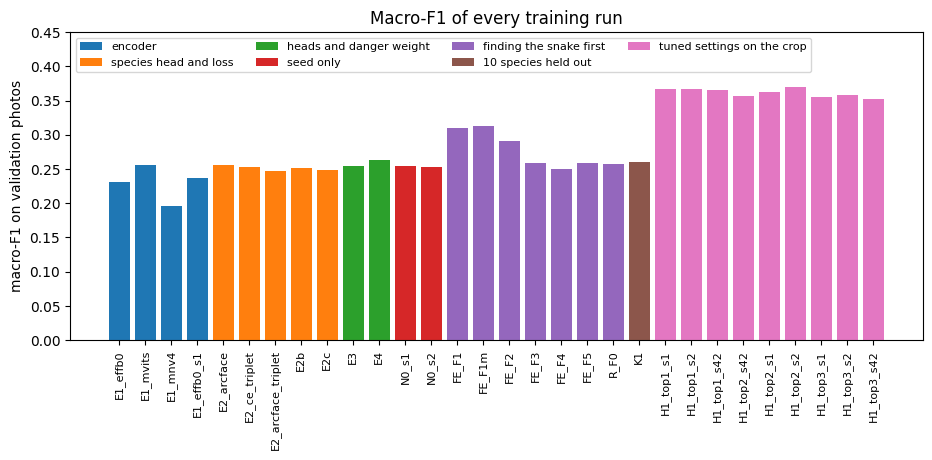

In [16]:
questions = {"E1": "encoder", "E2": "species head and loss", "E2b": "species head and loss",
             "E2c": "species head and loss", "E3": "heads and danger weight",
             "E4": "heads and danger weight", "N0": "seed only", "FE": "finding the snake first",
             "K1": "10 species held out", "retrain": "tuned settings on the crop"}
fig, ax = plt.subplots(figsize=(11, 4))
for question, part in runs.groupby(runs["stage"].map(questions), sort=False):
    ax.bar(part.index, part["macro-F1 head"], label=question)
ax.set(title="Macro-F1 of every training run", ylabel="macro-F1 on validation photos",
       ylim=(0, 0.45))  # headroom for the legend
ax.tick_params(axis="x", rotation=90, labelsize=8)
ax.legend(fontsize=8, ncol=4, loc="upper left")
plt.show()

## 4. Against the published model

B1 is the published SnakeCLEF 2021 model, and it knows 62 of our 184 species. The baselines notebook's appendix scored it and our final model with the same scoring function, on all 184 species and on those 62, and saved the table read here; its two checks (the scoring reproduces our run's own macro-F1, and shuffled labels fall to chance) run there. *Closed set* means our model may only answer with one of B1's 62 species. The second half repeats everything on the photos uploaded from 2022 on, which B1 cannot have trained on.

In [17]:
b1 = pd.read_csv(results / "summary" / "b1_comparison.csv")
b1.set_index(["evaluation", "species", "model"])

macro-F1  top-1  top-3  \
evaluation         species     model                                      
full validation    all 184     ours                 0.367  0.622  0.762   
                   62 B1 knows ours                 0.568  0.682    NaN   
                   all 184     B1                   0.257  0.683  0.771   
                   62 B1 knows B1                   0.653  0.801    NaN   
                               ours, closed set       NaN  0.701    NaN   
uploaded from 2022 all 184     ours                 0.357  0.617  0.756   
                   62 B1 knows ours                 0.560  0.679    NaN   
                   all 184     B1                   0.252  0.674  0.767   
                   62 B1 knows B1                   0.637  0.788    NaN   
                               ours, closed set       NaN  0.697    NaN   

                                                 mean recall  
evaluation         species     model                          
full validation    all 184     ours                      NaN  
                   62 B1 knows ours                    0.585  
                   all 184     B1                        NaN  
                   62 B1 knows B1                      0.755  
                               ours, closed set        0.603  
uploaded from 2022 all 184     ours                      NaN  
                   62 B1 knows ours                    0.577  
                   all 184     B1                        NaN  
                   62 B1 knows B1                      0.737  
                               ours, closed set        0.594

Over all 184 species our model is far ahead on macro-F1 (0.367 against 0.257), because B1 cannot name the 122 species it never learned; top-1 over all photos still favours B1 (0.683 against 0.622), since most photos show common species it knows. On B1's own 62 species B1 is clearly better: macro-F1 0.653 against 0.568 and top-1 0.801 against 0.682, or 0.701 when ours may only choose among those 62. The 2022 photos show the same gap, so B1's lead does not come from having seen our validation photos.

## What we found

The final model, MobileViT-S with an ArcFace species head and genus, family and WHO heads, trained on the detector's crop with tuned settings, reaches macro-F1 0.367 and top-1 0.622 over all 184 species on the validation photos. Two changes made most of the gain: cropping to the snake (+0.053) and tuning (+0.056); the encoder choice added 0.022, while the head, losses and loss weights each moved the score by less than 0.01. Segmenting the snake did not beat a plain crop, so the app needs only the small detector. The final recipe is stable across seeds (spread 0.0014), well inside the 0.005 noise floor. Against the published model we cover all 184 species, but on its own 62 species it is still clearly better.